# 第 02 章《逼近的智慧》B2 独立验证

G22 · 首轮 · 2026-11-11

[验证报告](B2组-验证报告.md) · [修正清单](B2组-修正清单.md) · [AI 对话记录](B2组-AI对话记录.md)

本 Notebook 用解析式、高精度 Newton 差商和 SVD 投影复核两稿。A 稿数据来自同日三份原 Notebook 在独立环境中的重新运行。下面的代码可以从头运行，直接重算参考量并与这些实测数据比较。

运行环境为 Python 3.12、NumPy 1.26.4、Matplotlib 3.9.2。网络复核使用首轮训练所得权重和解析链式公式，训练设置、重跑方法及覆盖范围见报告。组员对证据的签认待完成。

In [1]:
from decimal import Decimal, localcontext
from fractions import Fraction
from math import cos, exp, fsum, log2, pi, sin, sqrt, ulp
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "figure.dpi": 115,
})

## 版本、运行状态和预先登记的判据

A1 固定 [5d3ec4d66845131c1800654330ee9e3d0785e305](https://github.com/prince19992516/-2026/commit/5d3ec4d66845131c1800654330ee9e3d0785e305)，A2 固定 [a363a72c8f26d86cd6f129d3db0c3e63e2778729](https://github.com/prince19992516/-2026/commit/a363a72c8f26d86cd6f129d3db0c3e63e2778729)。

原 Notebook 执行前登记解析参考和容差。Runge 网格最大误差用绝对容差 $10^{-10}$ 和相对容差 $2\times10^{-5}$，给高次数等距插值留出舍入余量。低次精确插值、满秩线性拟合与 AD 的解析核验用 $10^{-12}$。稳定的最小二乘数值对照用绝对容差 $10^{-10}$、相对容差 $10^{-8}$。$x^2$ 梯形闭式用 $10^{-14}$。四位小数差商的末位容差为 $5\times10^{-5}$。同一网络权重的输入导数核对用 $10^{-10}$。

下一单元保存重跑证据中的数值和权重，以便复算。测试网格的最大值是离散观测。两稿网格、次数或训练设置有差别时，分别与本稿参考条件对照。

In [2]:
# 本轮 A 稿重跑数据与实际模型权重。
evidence = {'runs': [{'name': 'A1组-实验.ipynb',
           'commit': '5d3ec4d66845131c1800654330ee9e3d0785e305',
           'blob': '9026abe484c2ce8a9a86e682437bda50f432de78',
           'sha256': 'd87f511fb7296d9e2c71039d5c2ab976f8e5a48f022a459a715c44eb74c9053c',
           'cells': 12,
           'executed': 12,
           'errors': 0,
           'python': '3.12.14',
           'libraries': ['ipykernel==6.29.5', 'matplotlib==3.9.1.post1', 'nbclient==0.10.0',
                         'nbformat==5.10.4', 'numpy==2.0.1']},
          {'name': 'A2组-实验-2.1-2.2.ipynb',
           'commit': 'a363a72c8f26d86cd6f129d3db0c3e63e2778729',
           'blob': '253985e379ef06b38d57ae157b96e747a9abce73',
           'sha256': '13ad8467f0e4e9c12d871460b45b4ee403acfaf5b6ab7d4b287d8ae18ce4e1f3',
           'cells': 6,
           'executed': 6,
           'errors': 0,
           'python': '3.12.14',
           'libraries': ['ipykernel==7.4.0', 'matplotlib==3.9.2', 'nbclient==0.11.0', 'nbformat==5.11.1',
                         'numpy==1.26.4', 'scipy==1.14.1']},
          {'name': 'A2组-实验.ipynb',
           'commit': 'a363a72c8f26d86cd6f129d3db0c3e63e2778729',
           'blob': 'ffe76ed4b614f7a7467fdffd7b11424ac6d20e92',
           'sha256': 'c6b4db08bd1a9fcbe786e6cb508e85691aa81740f5342fa3bc6a716118eec593',
           'cells': 6,
           'executed': 6,
           'errors': 0,
           'python': '3.12.14',
           'libraries': ['ipykernel==7.4.0', 'matplotlib==3.11.2', 'nbclient==0.11.0', 'nbformat==5.11.1',
                         'numpy==2.5.4', 'torch==2.14.1+cpu']}],
 'a1': {'interpolation': {'rows': [{'n': 8,
                                    'nodes': 'equispaced',
                                    'grid_max_error': 1.0451765938537918,
                                    'node_max_error': 0.0},
                                   {'n': 8,
                                    'nodes': 'Chebyshev zeros',
                                    'grid_max_error': 0.17083555982584997,
                                    'node_max_error': 0.0},
                                   {'n': 16,
                                    'nodes': 'equispaced',
                                    'grid_max_error': 14.393763270429988,
                                    'node_max_error': 0.0},
                                   {'n': 16,
                                    'nodes': 'Chebyshev zeros',
                                    'grid_max_error': 0.032613573630504655,
                                    'node_max_error': 0.0},
                                   {'n': 32,
                                    'nodes': 'equispaced',
                                    'grid_max_error': 5059.0113712515595,
                                    'node_max_error': 0.0},
                                   {'n': 32,
                                    'nodes': 'Chebyshev zeros',
                                    'grid_max_error': 0.0014017422708303973,
                                    'node_max_error': 0.0}],
                          'grid_size': 6001,
                          'grid': 'shifted uniform interior grid of [-1,1], offset=.371, exact analytic '
                                  'target',
                          'baseline': '2x^2-x+3 at three nonnodes; direct Lagrange; 3 invalid inputs '
                                      'rejected'},
        'least_squares': {'rows': [{'basis': 'power',
                                    'condition_2': 16674.68568998169,
                                    'residual_2': 0.06932629866490654,
                                    'grid_max_error': 0.018921326467591815,
                                    'qr_prediction_max_difference': 1.1046719095020308e-14},
                                   {'basis': 'chebyshev',
                                    'condition_2': 2.458870848251713,
                                    'residual_2': 0.06932629866490687,
                                    'grid_max_error': 0.018921326467602473,
                                    'qr_prediction_max_difference': 3.1086244689504383e-15}],
                          'degree_comparison': [{'degree': 3,
                                                 'residual_2': 0.0777355590573643,
                                                 'grid_max_error': 0.011540653253069688},
                                                {'degree': 12,
                                                 'residual_2': 0.06932629866490687,
                                                 'grid_max_error': 0.018921326467602473},
                                                {'degree': 30,
                                                 'residual_2': 0.045376304393887186,
                                                 'grid_max_error': 28.21709303626089}],
                          'samples': 41,
                          'degree': 12,
                          'noise_std': 0.015,
                          'basis_prediction_max_difference': 1.7041923427996153e-14,
                          'normal_equations_solved': False,
                          'scaling_interval': [100.0, 102.0],
                          'rank_deficient_rejected': True},
        'differentiation': {'trapezoid': [{'N': 4,
                                           'T_N': 0.34375,
                                           'signed_error_I_minus_T': -0.010416666666666685,
                                           'absolute_error': 0.010416666666666685},
                                          {'N': 8,
                                           'T_N': 0.3359375,
                                           'signed_error_I_minus_T': -0.002604166666666685,
                                           'absolute_error': 0.002604166666666685},
                                          {'N': 16,
                                           'T_N': 0.333984375,
                                           'signed_error_I_minus_T': -0.0006510416666666852,
                                           'absolute_error': 0.0006510416666666852},
                                          {'N': 32,
                                           'T_N': 0.33349609375,
                                           'signed_error_I_minus_T': -0.00016276041666668517,
                                           'absolute_error': 0.00016276041666668517},
                                          {'N': 64,
                                           'T_N': 0.3333740234375,
                                           'signed_error_I_minus_T': -4.069010416668517e-05,
                                           'absolute_error': 4.069010416668517e-05}],
                            'x': 0.7,
                            'F': 2.4843785956416347,
                            'analytic_d1': 3.2490187095246466,
                            'analytic_d2': 2.85599168387525,
                            'dual_d1': 3.2490187095246466,
                            'reverse_d1': 3.249018709524647,
                            'jet_d2': 2.85599168387525,
                            'manual_reverse': {'bar_exp': 1.0,
                                               'bar_sin': 1.0,
                                               'bar_square': 0.8823328586101216,
                                               'bar_x': 3.2490187095246466},
                            'difference': {'h': [0.1, 0.05623413251903491, 0.03162277660168379,
                                                 0.01778279410038923, 0.01, 0.005623413251903491,
                                                 0.0031622776601683794, 0.0017782794100389228, 0.001,
                                                 0.0005623413251903491, 0.00031622776601683794,
                                                 0.00017782794100389227, 0.0001, 5.623413251903491e-05,
                                                 3.1622776601683795e-05, 1.778279410038923e-05, 1e-05,
                                                 5.623413251903491e-06, 3.162277660168379e-06,
                                                 1.778279410038923e-06, 1e-06, 5.62341325190349e-07,
                                                 3.162277660168379e-07, 1.7782794100389227e-07, 1e-07,
                                                 5.6234132519034905e-08, 3.162277660168379e-08,
                                                 1.7782794100389228e-08, 1e-08, 5.623413251903491e-09,
                                                 3.1622776601683795e-09, 1.7782794100389228e-09, 1e-09,
                                                 5.623413251903491e-10, 3.1622776601683795e-10,
                                                 1.778279410038923e-10, 1e-10, 5.6234132519034906e-11,
                                                 3.1622776601683794e-11, 1.7782794100389227e-11, 1e-11,
                                                 5.6234132519034904e-12, 3.1622776601683794e-12,
                                                 1.7782794100389228e-12, 1e-12, 5.62341325190349e-13,
                                                 3.162277660168379e-13, 1.7782794100389227e-13, 1e-13,
                                                 5.6234132519034906e-14, 3.1622776601683796e-14,
                                                 1.7782794100389227e-14, 1e-14, 5.623413251903491e-15,
                                                 3.1622776601683794e-15, 1.7782794100389227e-15, 1e-15,
                                                 5.623413251903491e-16, 3.1622776601683793e-16,
                                                 1.7782794100389228e-16, 1e-16],
                                           'forward_error': [0.13455903260760227, 0.0778332358335847,
                                                             0.04440033425482337, 0.025158606365852876,
                                                             0.014206337117979473, 0.008007060585118353,
                                                             0.0045084218554909405, 0.0025370720576614048,
                                                             0.0014272681296905176, 0.0008027910811270189,
                                                             0.000451499226533425, 0.00025391456999290796,
                                                             0.00014279231242575463, 8.029980665158476e-05,
                                                             4.5156466090379155e-05, 2.5393510860283186e-05,
                                                             1.4279836209052377e-05, 8.030132169878357e-06,
                                                             4.515591505160899e-06, 2.539371148024827e-06,
                                                             1.4274059783048187e-06, 8.030581106766022e-07,
                                                             4.5074851540150007e-07, 2.5384479895862455e-07,
                                                             1.355504668509866e-07, 8.046916155635131e-08,
                                                             4.0683166169230844e-08, 1.660156989657935e-08,
                                                             3.3409948585472193e-08, 6.3994551879886785e-09,
                                                             2.9533503642653613e-08, 1.5820923060516634e-07,
                                                             3.218614192945779e-07, 5.591997438436636e-07,
                                                             7.317001973206061e-07, 1.5820923060516634e-07,
                                                             4.3186643079451414e-06, 6.087202630400412e-06,
                                                             9.157700521456036e-06, 1.0147397821125281e-05,
                                                             1.764134060344702e-05, 5.347008451606072e-05,
                                                             9.341770376769531e-05, 0.0002848500840682,
                                                             0.0005061394714385159, 0.0009221562524226457,
                                                             0.0021999177849134632, 3.51203692980917e-05,
                                                             0.002726585520688829, 0.0032913003467132107,
                                                             0.005008584559774931, 0.02750538899397803,
                                                             0.007167477619189455, 0.011188447327681761,
                                                             0.019051918434081827, 0.002532417516996066,
                                                             0.14039424057420868, 0.8798746152341845,
                                                             0.4403519346632856, 0.7517215618264541,
                                                             3.2490187095246466],
                                           'central_error': [0.007302028578343833, 0.0023017033577823476,
                                                             0.0007271168043434528, 0.0002298597741634545,
                                                             7.26805623836313e-05, 2.2982863627785122e-05,
                                                             7.267744786876307e-06, 2.298255159960405e-06,
                                                             7.267713026948286e-07, 2.298251429166953e-07,
                                                             7.267743384886671e-08, 2.2984335767972652e-08,
                                                             7.268623036793542e-09, 2.300835966195791e-09,
                                                             7.236038435110004e-10, 2.3021318185101336e-10,
                                                             7.437828131173774e-11, 4.225197969276451e-11,
                                                             4.250200191791009e-11, 1.1940848310132424e-10,
                                                             1.1878675820753415e-10, 3.131197523487117e-10,
                                                             4.250200191791009e-11, 1.6177872375067182e-09,
                                                             2.117188202532816e-09, 5.446265216590973e-09,
                                                             1.4468355402641464e-09, 4.1150838292480785e-09,
                                                             3.3409948585472193e-08, 3.3086279493943493e-08,
                                                             2.9533503642653613e-08, 3.3344373040478104e-08,
                                                             9.981681436954659e-08, 1.6434239480389579e-07,
                                                             2.9533503642653613e-08, 1.5820923060516634e-07,
                                                             2.0982182586948284e-06, 2.1386291400027346e-06,
                                                             2.136033584676511e-06, 2.339087917579974e-06,
                                                             4.563119889056111e-06, 1.3984349611195768e-05,
                                                             2.3201034395903264e-05, 3.512036929853579e-05,
                                                             6.205026158845328e-05, 0.0005272989033744402,
                                                             0.0007955843974825072, 0.0012135282045511175,
                                                             0.0005061394714385159, 0.004605846634254895,
                                                             0.0020130823773785167, 0.002532417516996066,
                                                             0.015036982873313676, 0.028297287577159214,
                                                             0.05116475093745221, 0.12233243986791331,
                                                             0.08165036435082262, 0.09015991713736371,
                                                             0.2618147590520543, 0.4969270120226419,
                                                             1.0285726602743335],
                                           'best_central_h': 5.623413251903491e-06,
                                           'best_central_error': 4.225197969276451e-11}},
        'network': {'seed': 2026,
                    'device': 'CPU',
                    'dtype': 'float64',
                    'width': 12,
                    'parameter_count': 37,
                    'training_points': 81,
                    'test_points': 2001,
                    'test_grid': 'shifted uniform interior grid, offset=.371, disjoint from training points',
                    'steps': 14000,
                    'optimizer': 'Adam beta1=.9 beta2=.999 eps=1e-8; learning rate .01 for 8000 steps then '
                                 '.002',
                    'training_scope': 'all a,w,b,c jointly; value-only loss',
                    'final_loss': 1.0566416815609858e-06,
                    'train_grid_max_error': 0.0029083189444616296,
                    'independent_grid_max_errors': {'value': 0.0028647578849091684,
                                                    'first_derivative': 0.1171684955937482,
                                                    'second_derivative': 1.6469419116608754},
                    'jet_vs_analytic_max_differences': [9.992007221626409e-16, 1.7763568394002505e-15,
                                                        3.9968028886505635e-15],
                    'reverse_vs_analytic_parameter_gradient_max_differences': [5.421010862427522e-20,
                                                                               2.710505431213761e-20,
                                                                               4.0657581468206416e-20, 0.0],
                    'directional_gradient': {'reverse': -7.439810802329849e-05,
                                             'central_difference': -7.439811408383193e-05,
                                             'h': 1e-05,
                                             'absolute_difference': 6.060533436322464e-12},
                    'training_seconds': 2.2467412999999397,
                    'params': {'a': [-0.20325742820395268, -1.0877754156120847, -0.4862351882743994,
                                     0.598899778038808, 0.3093591192413919, -0.1686287784694143,
                                     0.5040899895913984, -1.1659604846350464, -1.16228631158289,
                                     0.0690777514260294, -0.6984322636757218, -1.2314753515316594],
                               'w': [-0.04820703311754782, 2.5447749344019206, 0.2693175333998367,
                                     -0.950494803790416, -0.18534450598223598, 0.37483654391650356,
                                     -0.3947133332148003, -2.284220232989256, -2.3892122440053196,
                                     1.0681315948709047, 0.7346360999709722, 1.7788099404837865],
                               'b': [0.513694850431136, 2.3738861175183867, 0.03934776795387678,
                                     0.9179269125411091, -0.7551759541524486, 0.14247211746032795,
                                     0.004783403494990235, 0.5668570669499501, -0.32852613779057327,
                                     0.042926551777351836, -0.5928201427437104, -1.7507711429479325],
                               'c': -0.3341248786383958},
                    'counterexamples': {'high_frequency': {'k': 100,
                                                           'epsilon': 0.0001,
                                                           'continuous_sup_errors': [0.0001, 0.01, 1.0]},
                                        'relu': {'formula': 'max(0,x): derivative 0 for x<0 and 1 for x>0; '
                                                            'not differentiable at 0',
                                                 'second_difference_away': [0.0, 0.0],
                                                 'kink_second_difference': [9.999999999999998, 100.0,
                                                                            1000.0000000000001],
                                                 'kink_steps': [0.1, 0.01, 0.001]}}}},
 'a2_first': {'environment': {'python': '3.12.14',
                              'numpy': '1.26.4',
                              'scipy': '1.14.1',
                              'matplotlib': '3.9.2',
                              'seed': 2026,
                              'dtype': 'float64',
                              'device': 'CPU',
                              'blas_threads': [{'internal_api': 'openblas', 'num_threads': 1},
                                               {'internal_api': 'openblas', 'num_threads': 1}]},
              'interpolation': [{'n': 5,
                                 'equidistant_max_error': 0.4383566395255678,
                                 'chebyshev_max_error': 0.40201674193790876,
                                 'ratio': 1.0903939905897544},
                                {'n': 9,
                                 'equidistant_max_error': 1.0451739117836971,
                                 'chebyshev_max_error': 0.1708355947318404,
                                 'ratio': 6.118010204046178},
                                {'n': 11,
                                 'equidistant_max_error': 1.915643050219249,
                                 'chebyshev_max_error': 0.10915326641231005,
                                 'ratio': 17.550029542709197},
                                {'n': 15,
                                 'equidistant_max_error': 7.1948811072330665,
                                 'chebyshev_max_error': 0.04660207211184908,
                                 'ratio': 154.38972520287763},
                                {'n': 21,
                                 'equidistant_max_error': 59.82230871072824,
                                 'chebyshev_max_error': 0.015333731976079568,
                                 'ratio': 3901.353486812623},
                                {'n': 31,
                                 'equidistant_max_error': 2387.9977363715934,
                                 'chebyshev_max_error': 0.0020615444251730897,
                                 'ratio': 1158353.7600316782}],
              'probe': {'x': 0.95,
                        'equidistant': 1.9236311497191985,
                        'chebyshev': 0.08553493133811099,
                        'reference': 0.042440318302387266,
                        'peak_abs_x': 0.94},
              'conditioning': {'3': [105.46868405577776, 1.8209837078957638],
                               '6': [18193.277373303692, 1.8450466434022066],
                               '9': [4628254.574792925, 2.9876216266349007],
                               '12': [2412655790.131009, 16.51079897866209]},
              'normal_equation': {'condition': 21418515536462.953,
                                  'coefficient_max_difference': 4.948739531315368},
              'degree_errors': {'1': {'train_max_residual': 0.13858364873496987,
                                      'test_max_error': 0.1337561590550007},
                                '2': {'train_max_residual': 0.05238331868605339,
                                      'test_max_error': 0.013655183092950995},
                                '3': {'train_max_residual': 0.05168196381411816,
                                      'test_max_error': 0.020447315449083292},
                                '6': {'train_max_residual': 0.052027048778176876,
                                      'test_max_error': 0.025301629850656537},
                                '9': {'train_max_residual': 0.0341895042873237,
                                      'test_max_error': 0.031504935130918454},
                                '12': {'train_max_residual': 0.005638855118140551,
                                       'test_max_error': 0.17640854565201702},
                                '14': {'train_max_residual': 1.6557985782483797e-07,
                                       'test_max_error': 0.968846924422901}},
              'evaluation_overlap': {'training_points': 15,
                                     'evaluation_points': 400,
                                     'shared_endpoints': 2,
                                     'shared_points': 8,
                                     'remaining_points': 392}},
 'a2_last': {'environment': {'python': '3.12.14',
                             'numpy': '2.5.4',
                             'torch': '2.14.1+cpu',
                             'matplotlib': '3.11.2',
                             'system': 'Windows',
                             'machine': 'AMD64',
                             'device': 'CPU',
                             'dtype': 'float64',
                             'threads': 1,
                             'seed': 2026},
             'quadrature': [{'n': 4,
                             'T_n': 0.34375,
                             'abs_error': 0.010416666666666685,
                             'theory': 0.010416666666666666,
                             'ratio': None,
                             'order': None},
                            {'n': 8,
                             'T_n': 0.3359375,
                             'abs_error': 0.002604166666666685,
                             'theory': 0.0026041666666666665,
                             'ratio': 3.9999999999999787,
                             'order': 1.9999999999999922},
                            {'n': 16,
                             'T_n': 0.333984375,
                             'abs_error': 0.0006510416666666852,
                             'theory': 0.0006510416666666666,
                             'ratio': 3.9999999999999147,
                             'order': 1.9999999999999694},
                            {'n': 32,
                             'T_n': 0.33349609375,
                             'abs_error': 0.00016276041666668517,
                             'theory': 0.00016276041666666666,
                             'ratio': 3.999999999999659,
                             'order': 1.999999999999877},
                            {'n': 64,
                             'T_n': 0.3333740234375,
                             'abs_error': 4.069010416668517e-05,
                             'theory': 4.0690104166666664e-05,
                             'ratio': 3.9999999999986358,
                             'order': 1.999999999999508},
                            {'n': 128,
                             'T_n': 0.333343505859375,
                             'abs_error': 1.017252604168517e-05,
                             'theory': 1.0172526041666666e-05,
                             'ratio': 3.999999999994543,
                             'order': 1.9999999999980318}],
             'exp_orders': [1.9988742555775347, 1.9997183087703503, 1.9999295612348986, 1.999982389280256,
                            1.9999955973284533],
             'differentiation': {'x': 0.7,
                                 'reference': 3.2490187095246466,
                                 'ad': 3.2490187095246466,
                                 'ad_error': 0.0,
                                 'grid_ad_error': 4.440892098500626e-16,
                                 'central_difference': [{'h': 0.1,
                                                         'central_difference': 3.2417166809463027,
                                                         'abs_error': 0.007302028578343833},
                                                        {'h': 0.01,
                                                         'central_difference': 3.248946028962263,
                                                         'abs_error': 7.26805623836313e-05},
                                                        {'h': 0.001,
                                                         'central_difference': 3.249017982753344,
                                                         'abs_error': 7.267713026948286e-07},
                                                        {'h': 0.0001,
                                                         'central_difference': 3.2490187022560235,
                                                         'abs_error': 7.268623036793542e-09},
                                                        {'h': 1e-05,
                                                         'central_difference': 3.2490187094502683,
                                                         'abs_error': 7.437828131173774e-11},
                                                        {'h': 1e-06,
                                                         'central_difference': 3.24901870940586,
                                                         'abs_error': 1.1878675820753415e-10},
                                                        {'h': 1e-07,
                                                         'central_difference': 3.2490187074074584,
                                                         'abs_error': 2.117188202532816e-09},
                                                        {'h': 1e-08,
                                                         'central_difference': 3.249018742934595,
                                                         'abs_error': 3.3409948585472193e-08},
                                                        {'h': 1e-09,
                                                         'central_difference': 3.249018609707832,
                                                         'abs_error': 9.981681436954659e-08},
                                                        {'h': 1e-10,
                                                         'central_difference': 3.249016611306388,
                                                         'abs_error': 2.0982182586948284e-06},
                                                        {'h': 1e-11,
                                                         'central_difference': 3.2490232726445356,
                                                         'abs_error': 4.563119889056111e-06},
                                                        {'h': 1e-12,
                                                         'central_difference': 3.248956659263058,
                                                         'abs_error': 6.205026158845328e-05},
                                                        {'h': 1e-13,
                                                         'central_difference': 3.248512570053208,
                                                         'abs_error': 0.0005061394714385159},
                                                        {'h': 1e-14,
                                                         'central_difference': 3.2640556923979602,
                                                         'abs_error': 0.015036982873313676},
                                                        {'h': 1e-15,
                                                         'central_difference': 3.330669073875469,
                                                         'abs_error': 0.08165036435082262},
                                                        {'h': 1e-16,
                                                         'central_difference': 2.220446049250313,
                                                         'abs_error': 1.0285726602743335}]},
             'network': {'architecture': '1-32-32-1, tanh',
                         'parameters': 1153,
                         'train_points': 41,
                         'test_points': 400,
                         'train_mse': 4.53113284558362e-08,
                         'adam_steps': 2000,
                         'lbfgs_max_iter': 400,
                         'lbfgs_closures': 470,
                         'seconds': 10.827279799999815,
                         'errors': [{'quantity': 'u',
                                     'max_abs_error': 0.00041346682125675827,
                                     'rmse': 0.00021407220620395806,
                                     'relative_l2': 0.00030274381734076734},
                                    {'quantity': 'du_dx',
                                     'max_abs_error': 0.015226983221500845,
                                     'rmse': 0.004264003594971782,
                                     'relative_l2': 0.0019194760043528259},
                                    {'quantity': 'd2u_dx2',
                                     'max_abs_error': 0.35618107375732405,
                                     'rmse': 0.0923873138694857,
                                     'relative_l2': 0.013238158993588994}],
                         'ad_manual_errors': [4.440892098500626e-16, 1.3322676295501878e-15,
                                              5.329070518200751e-15],
                         'poisson_residual_rmse': 0.0923873138694857,
                         'boundary_values': [-0.00014852387381744658, 4.511195555251257e-05],
                         'residual_parameter_gradient_norm': 0.5223205006066282},
             'counterexample': [{'k': 10,
                                 'value_error_at_witness': 0.1,
                                 'first_error_at_zero': 1.0,
                                 'second_error_at_witness': 10.0},
                                {'k': 100,
                                 'value_error_at_witness': 0.01,
                                 'first_error_at_zero': 1.0,
                                 'second_error_at_witness': 100.0},
                                {'k': 1000,
                                 'value_error_at_witness': 0.001,
                                 'first_error_at_zero': 1.0,
                                 'second_error_at_witness': 1000.0}]},
 'a1_edge': [2.8757999999999995, 4.32],
 'a2_weights': {'0.weight': [[-0.7081595947894913], [0.7014206300920706], [-0.8438753836315472],
                             [-1.0790536092221488], [0.3778768393260705], [0.3988591442658929],
                             [0.7379233503648298], [-0.7585907755791822], [-0.6524284355212286],
                             [-1.1159563587900938], [-0.19662327384102418], [0.47446879494664923],
                             [-0.9719188760521887], [-0.9205888094426756], [0.419701008254834],
                             [-0.020810906711982956], [0.7465045763878873], [0.989018631389555],
                             [-0.5824803105007865], [-1.1201192781268958], [0.4388402800051432],
                             [0.3728505945280218], [1.0931659895009582], [0.45525319542166126],
                             [-0.7511744595218437], [-0.8903374193721652], [-0.26429511671793204],
                             [-1.0894394106239502], [0.2838356328165224], [0.995876353617914],
                             [1.1338374997555156], [0.43783845797070997]],
                '0.bias': [-0.06468536103831196, -0.21875920837368848, -0.6170036702489832,
                           -0.1506752418234219, -0.12496849181235574, 0.6706175071194275, -0.3603783547077879,
                           0.029930453383158258, 0.8281336751549845, 0.2859151736524434, -0.7109397018913552,
                           -0.659701688780706, -0.7096292967963976, 0.9175232158188692, -0.6396081926901376,
                           -0.8743204514786309, -0.7164026647235837, 0.4979689379465898, -0.6862793882442032,
                           0.18139338323715073, 0.773830861432671, -0.3620022478207975, -0.32850183798205845,
                           0.8618399487586604, -0.20489486374908494, -0.08470349107048016,
                           -0.6406764273422805, 0.111340825188014, 0.21359442395729894, 0.5468319194517001,
                           -0.6101671705209301, -0.43633989870386297],
                '2.weight': [[0.07856425680592846, -0.1683274011647884, 0.15352575356940726,
                              0.07913145264623356, -0.06466182783058003, 0.039378522930216896,
                              0.05902742488914091, -0.01517132304542797, -0.08231832168943753,
                              0.09481208366252881, 0.15859449210280496, 0.07314492956166906,
                              0.016367623739151467, 0.023898926861944524, -0.1446773802979352,
                              0.14047249229623648, 0.10405684736602663, -0.04560125055788065,
                              0.22536363594498063, -0.19413218592505482, -0.0055022617848176055,
                              -0.18727730933887898, -0.1444410550888975, -0.015933248202463706,
                              -0.07806089242705545, -0.008525529421717708, 0.14476562627390788,
                              -0.066663584631829, -0.15321336867373556, 0.018536935256386052,
                              -0.13962957551496905, 0.03144771900812695],
                             [0.13410581205554692, -0.004105307322934275, 0.19588285646847084,
                              0.14263802428381364, 0.11777574640685076, -0.24772998810468927,
                              -0.102033422030631, -0.13599121560741373, -0.03563877684108285,
                              0.13286143701890787, -0.14395041011638013, 0.020743007644733354,
                              -0.02887997226470019, 0.022175606415853023, -0.040929754784109686,
                              -0.06516453534899995, 0.11798658760260698, -0.043614180393741576,
                              -0.09789759201665912, 0.1146642728264521, -0.06714200632089914,
                              -0.15862342407854044, 0.14948394954395097, -0.1010755347320914,
                              -0.0763687955803263, 0.15018665125209818, -0.08045735684336976,
                              -0.17711245044148322, -0.11429980105876565, -0.12912627324695938,
                              0.1361191269577019, -0.049648676228701734],
                             [-0.02660163276219654, -0.08006877016351097, 0.19130018023300768,
                              0.07594384826112872, -0.23428163235544525, 0.01903313411268438,
                              -0.2706862879791915, 0.17626098786606026, 0.31369542603825784,
                              0.0033881090925096794, 0.1294436805674824, -0.3090474318148642,
                              0.25078638029884176, 0.1825733901197613, 0.049263681707669454,
                              -0.14760568008029432, -0.21051856628424817, -0.19151645416473198,
                              0.17685841456755033, 0.1383052572382008, -0.0462107952466829,
                              -0.21716598755274072, -0.2659319084433858, 0.07735325398595883,
                              0.04737689298480509, 0.04336690296582046, 0.07936297131388195,
                              0.2845764171370055, -0.16814252855926445, -0.236319760302848,
                              -0.2505773844602136, -0.21976827853925882],
                             [0.1573495142843789, -0.18406942546524796, 0.09721211604313217,
                              -0.0013017200504057919, -0.10811965889748619, -0.12507179521596412,
                              -0.047072732877352357, -0.07945923972309447, -0.08559668907763324,
                              -0.07295724952815948, -0.029605311598898648, 0.05913697391428859,
                              0.2014305681480046, -0.015270296908936167, -0.13638805490979486,
                              0.06775511895001174, 0.10365623213777268, -0.2718434326207072,
                              0.3064894490105585, 0.16079520108491044, -0.18698283849734035,
                              -0.07104036440453476, 0.06074888283694717, -0.22489145676336716,
                              0.23774681017244567, 0.13270011422395345, 0.2703408148149751,
                              0.03204665227390503, -0.4650503386431978, -0.02790101816799095,
                              0.10225979291477354, 0.028287817957425205],
                             [0.11793866283165497, -0.057962460050321754, -0.08365053858595811,
                              -0.014709351472369882, -0.17241927810250895, 0.06476956590767864,
                              -0.2854904969414001, 0.1921891922621114, 0.15270940550151818,
                              -0.04952154481777037, 0.0834509954473043, -0.25773508350883556,
                              -0.07435713556891735, 0.36980320043642245, -0.2576819641529441,
                              -0.3326065163283226, -0.37885244887161007, -0.0353073617729867,
                              0.09512022154513416, 0.04364331102589286, 0.08044754867084584,
                              -0.2764201158581354, -0.10641648206293411, -0.14115714416413422,
                              0.11432126243488669, 0.007071732681847434, 0.09995443682976501,
                              0.10992296162383483, -0.433833400139084, 0.0998786857653219,
                              -0.03179855849666106, -0.131249775463725],
                             [-0.27472714344346727, 0.11388508487290742, 0.07551888043493844,
                              0.011063283057769687, 0.22007951659270478, 0.13677779002302426,
                              0.19033532567898084, -0.15032153979902518, -0.07679591952362404,
                              -0.08633511221833123, -0.03267018995038899, 0.0932251309461718,
                              0.10426011230759442, -0.18859510038588637, -0.06599983100993406,
                              0.10302652593313129, 0.15255772921584418, 0.17291737007041696,
                              -0.10385517925562747, -0.18199894960587656, -0.0011260560345837973,
                              0.050085636326356715, 0.17763639874418455, 0.04292840349384549,
                              -0.14911288240774803, -0.19214769853736974, -0.08611541649246444,
                              -0.053200199509474994, 0.32767743909013836, 0.1705464931189261,
                              0.29257041073849527, 0.14826307467178745],
                             [0.10099777900776527, -0.06703118309348559, 0.03263386682057709,
                              0.031891529084772885, -0.035760465870192534, 0.15018606047591002,
                              0.06251384909323313, 0.02542598982058897, -0.17833536835340358,
                              0.11727805372094088, -0.020934665814154686, 0.07788820076968178,
                              -0.09903487227968297, 0.0844600083654198, 0.026275213434198502,
                              0.03800478666263292, 0.1608365780583056, -0.12696408468422826,
                              -0.275024162880406, -0.12285673953852592, 0.24556721852101276,
                              0.033641844474279425, 0.010339157458485654, 0.03255650053353658,
                              0.06598647031469101, -0.09237322785793638, 0.07900128298505053,
                              -0.004601819201435914, 0.008992864919851747, 0.05668107739653353,
                              0.1716063659368742, -0.12291649446056327],
                             [-0.07343878465559647, 0.010591067460100882, -0.11565069726244284,
                              -0.08165995277705317, 0.20976908857367768, 0.21927948010975393,
                              0.1333977172406067, 0.14085102451350182, 0.030142064057250065,
                              0.03106969032871858, 0.11026560877128654, -0.09153550654569226,
                              -0.06288985395099135, -0.09328975882636527, 0.04716443848568441,
                              0.09325358001381392, 0.045835743146926934, 0.12980893889332518,
                              -0.07850916282020197, 0.18406052670075346, -0.086234440648509,
                              0.04494180543445978, 0.02038856523477113, -0.07641808920588151,
                              0.16024860630274015, 0.15439636678639782, -0.026824805536092813,
                              -0.03774476532248168, 0.095293592160062, 0.13573568308925488,
                              0.12076793670514946, 0.1465163841977918],
                             [0.08990219509329524, 0.06768102063793756, -0.10319230662467663,
                              0.20616223691266394, -0.0003679159062800601, 0.06527646317065845,
                              -0.16862479191240667, -0.1062068405959074, -0.16228482352074022,
                              -0.020103265169896578, 0.1677118698581168, 0.08647102705345464,
                              -0.10055773856199769, 0.019117149189851756, -0.013192367140798364,
                              -0.014937756539599467, -0.09957097950502244, -0.0038051624517006196,
                              0.08319453684884644, -0.0200611564940255, -0.07961586921005007,
                              -0.05034138643488973, -0.08036237517587885, 0.023152619203760282,
                              -0.04737994995028015, 0.05594840693709857, -0.008090367124384426,
                              0.16775768252900655, 0.16222711861260092, 0.06545203199598569,
                              0.10834055497002526, -0.022742508789513574],
                             [0.09048259285601792, -0.20301932569716594, 0.35931874579448064,
                              0.2635990257223403, -0.16016788310552124, -0.4249414999330053,
                              0.0401906861844637, 0.020185345266107303, -0.17055459272903664,
                              -0.010522602830364346, 0.1312456827749759, 0.09381625534338972,
                              0.47138110259624677, -0.15610658757326887, 0.11905800540688427,
                              0.33108751051865776, -0.14412169666867367, -0.39486861599558265,
                              0.3667987378192045, 0.1908622286023261, -0.45359716990722543,
                              0.04291452474089705, -0.019799192999381845, -0.4144492223471517,
                              0.25594585393281266, 0.22366492583824343, 0.2524221203393501,
                              -0.043639764118216365, -0.4623778093059251, -0.35921039003832045,
                              -0.02072739645168297, -0.2660920170378657],
                             [-0.17003589462713842, 0.15000116803626723, -0.05068460004292411,
                              0.03399117187915721, -0.21310062347030836, -0.20774998437590156,
                              0.027772385367848207, -0.1495484243374068, 0.15096402981926405,
                              0.07510929450129016, 0.13812972654945424, 0.02525887897022006,
                              -0.09041748641882832, 0.10253716644652071, -0.11535864811593587,
                              0.09502562024318352, -0.0645559755652533, 0.14790356826999987,
                              0.2380829774133421, -0.1633886911537505, -0.031925587083377296,
                              -0.010050837641316488, -0.11875918052913713, 0.0810093541806016,
                              -0.0276745224506338, -0.026520070342169442, 0.04732436224790033,
                              0.03302841196224274, -0.0155945745258302, -0.02772465332583495,
                              0.05031005434747267, -0.04968412560663263],
                             [-0.03255222188854873, 0.22067032573006515, -0.05422287441808186,
                              -0.3229689470449319, 0.2524403849555891, 0.3957580318332658,
                              0.15981130299752366, -0.3047928165602059, -0.21621653162755222,
                              -0.0907143658763684, -0.46333762607918, 0.24985621644506176,
                              -0.38444556625618065, -0.14675095707789226, -0.07441243034268637,
                              -0.18590424472003755, 0.14813462247591475, 0.06913226534869647,
                              -0.3908135681452983, -0.26315227418379344, 0.3076435227001357,
                              0.12877007090893622, 0.31017094992745725, 0.3920609751929472,
                              -0.22547336787722688, -0.20122408227524705, -0.32387706567330526,
                              -0.2601579508021556, 0.30620599237342194, 0.3497815596814503,
                              -0.02655036335741786, 0.30823384436847723],
                             [-0.08537476308041853, 0.18841677898208833, -0.21991995510768597,
                              0.0029697621154049455, 0.0799938264738572, 0.2545420088771093,
                              -0.04722896732652279, -0.007649081477971192, 0.08594438783658372,
                              -0.05318855013542004, -0.05185001450952259, 0.006438147593029885,
                              -0.15294066792697605, -0.13663734009876494, 0.043789803333558475,
                              0.006372112404045853, 0.2014614849300228, -0.027519475429542653,
                              -0.15080346472097658, 0.10886981117275984, 0.01771712105392559,
                              0.05583548347692214, -0.13864874344917574, -0.06090954679577484,
                              -0.0982245490551338, 0.10657632563223596, -0.23566424953730314,
                              0.0407009412680076, 0.2597741333481501, -0.05651164794502283,
                              -0.154276326883892, 0.20724862761816898],
                             [0.11086112465522918, -0.15572445343098393, -0.14913515179647374,
                              0.08003613849184871, 0.06450457628597032, -0.00869937611782195,
                              0.024341748777729655, 0.04841079097249997, 0.17057256830657336,
                              -0.028348989983176205, -0.10198184376949655, 0.09151963643249653,
                              0.1821541105583221, 0.014078994009678374, 0.08391880285978293,
                              -0.017267939705306455, -0.07897249742829014, -0.1759949635263014,
                              -0.011754086774679097, -0.033022163047463214, -0.08673350442104084,
                              0.026673142741621667, 0.11218399256644368, -0.12226802819104447,
                              0.1923312124514928, 0.1629519515301224, -0.042943094401600906,
                              0.168006436415931, 0.017826697352846237, 0.027392700458292854,
                              -0.012550078009484454, -0.16323610532094981],
                             [-0.05328232704942582, 0.12500042144706414, 0.05008341426814728,
                              0.08681931363626236, 0.19355270301183616, 0.06203363454251355,
                              -0.11053326708042524, -0.05746286971030821, -0.11655701849673376,
                              0.17832977157251298, -0.07703698310441867, -0.012938004826818155,
                              0.005216178069420425, -0.2086199537045068, 0.10560705432144532,
                              0.24254687588931792, 0.19689683644597497, 0.1399822017834213,
                              0.013796243174357436, -0.06728950260804001, -0.04134193315174376,
                              -0.08903141440865367, -0.18675570413931314, 0.040346857610907005,
                              -0.03489589341401862, -0.08972501545337941, 0.02365845671428663,
                              -0.06943218335777683, 0.16648889496078048, 0.04843533507335916,
                              0.14828702961497292, -0.03560650939023618],
                             [0.11375957474266264, 0.17645716871589953, -0.045300677625181626,
                              0.016279701247088975, -0.01755580781799853, 0.13902042260952477,
                              -0.03598176553557158, 0.12781532969499382, -0.20294454102696072,
                              0.06325843770805385, -0.17368741874591456, 0.15868229618349733,
                              -0.16787498157423064, -0.041893915586005574, 0.176134468299738,
                              -0.08893209474217845, 0.0034630841258488777, 0.12528415645123353,
                              0.0919069825563491, 0.15501586723531172, -0.08308379348174512,
                              0.1023350830307012, -0.03115782566587095, -0.04727619065232457,
                              -0.033325573160539815, -0.16570623862540343, -0.1835561352447158,
                              0.07469424542057963, 0.3486358368854786, -0.0321665398773718,
                              0.03312438019204474, -0.05248145326758667],
                             [-0.0978924250541679, 0.14303409632879666, -0.30379179205388457,
                              -0.13867744098118173, 0.1807051173707914, 0.450233610170719, 0.2163652540906618,
                              -0.18800358569452694, 0.30587963061728857, 0.011045759375706931,
                              -0.40064517074264283, 0.021802900020287497, -0.49050232160289625,
                              0.09601911655121739, -0.00947964842252526, -0.34293016816445,
                              -0.15128801982516818, 0.4371058773986492, -0.24965822141752078,
                              0.07092727382156504, 0.5715503176304985, 0.12638237083986104,
                              -0.0232366213134544, 0.4094087686257274, -0.3867750234280715,
                              -0.3340139623992051, -0.5570071059863092, -0.2157056524194981,
                              0.45646656964840776, 0.48300058627743175, -0.0713348951999859,
                              0.05203559377094401],
                             [-0.042584287891264644, 0.10107454790500037, 0.0021385679813478646,
                              -0.033903753853481024, 0.0022510742844986395, 0.18204790525688483,
                              0.018179504141125763, -0.09797285664420612, -0.2695904194576748,
                              0.0856649654558759, -0.15907651201863404, -0.09402878752832274,
                              -0.22930478492373685, -0.003486570948398585, 0.10172364217873589,
                              0.03633455659532346, -0.020099592415083318, 0.10666175832322532,
                              -0.15464077645240454, 0.022506572428572336, -0.040287940307997205,
                              0.024497152842794977, 0.1598459599353433, 0.015367251893715878,
                              0.10363406117370527, 0.02148813967150444, -0.021076785278824908,
                              0.1611806300732266, 0.18029617934309866, -0.12491821562568127,
                              -0.10518349749750439, 0.1587228193780607],
                             [-0.1843393716189852, 0.18902143302267121, -0.19298483743019376,
                              -0.31935514476124566, 0.1808443320236303, 0.15035630778861653,
                              0.13476772171314105, -0.1639311824520637, -0.2557566423369119,
                              -0.27223738911183376, -0.1877086572310023, -0.0003344628550971345,
                              -0.29841273137019375, -0.19756443796081108, 0.1254488729728823,
                              -0.13463338668588987, 0.10711971748793947, 0.31700290439212636,
                              -0.09673159171879463, -0.0741900227545366, 0.3625571649812237,
                              0.14529771007503917, 0.17469710956226583, 0.3041988436012164,
                              -0.2750306799065768, 0.017553282855994192, 0.01796281403650177,
                              -0.28113247375530404, -0.03625489175304337, -0.0001357235053705418,
                              0.09732364536833997, 0.11206394187727461],
                             [0.02858446239341329, -0.0485845072426484, 0.1645925666077126,
                              -0.06565598244913382, 0.06814051484568912, -0.17042292591749408,
                              -0.0873001066682101, -0.120340212928524, -0.05358236117008726,
                              -0.1147303299670673, -0.06744270420139226, 0.058669398585831964,
                              0.006734085147813868, 0.18764485186894775, 0.058887709374860334,
                              0.01319477489336128, -0.16941143656900184, -0.02222320517624444,
                              0.12516762319045852, -0.07528323777579828, -0.04998797404626997,
                              0.008008309891739361, 0.07432873196137059, 0.02918783898004566,
                              0.08100139978918797, 0.023795691450742895, -0.1090694417595777,
                              0.1461771535626367, 0.018991050862752656, 0.030959613509124115,
                              0.12264191023931378, -0.012362178262201437],
                             [0.1510970705116456, -0.0046576336276628215, 0.28725469947136095,
                              -0.014404131809950855, -0.039970641914448185, -0.45259695067536154,
                              -0.15890541827356172, -0.012406106966556415, 0.21063822622324155,
                              -0.05255719400246468, 0.10331504967696321, 0.024150410417808715,
                              0.026821478476223258, -0.06648264452903346, -0.24946837078876705,
                              0.18011665125892262, -0.21773831924083656, -0.09585072668771641,
                              0.2658757696076621, 0.009630543867347385, -0.3478347826826443,
                              -0.0002636735790227959, 0.21284149047191897, -0.19413217212615375,
                              0.21228544062030574, 0.15340419922062323, 0.15050427221486706,
                              -0.19619263769129874, -0.44026790446640374, 0.017991449915663624,
                              0.22728996233919763, -0.15428518545566738],
                             [0.16763305073761745, -0.026407652804002195, 0.049341718028671135,
                              -0.10196940289255013, -0.03025649154840162, -0.23918279920878982,
                              -0.09130491574965736, 0.023167515961185582, -0.002089369375667125,
                              -0.19322025102222098, 0.10800124159910685, -0.05334128044728199,
                              0.16693840447105737, 0.0913553475373023, -0.10620658434253231,
                              0.1664765839990783, -0.09928280123108794, 0.0008203401677772714,
                              0.27892994393669046, -0.005200265673426333, -0.26492086301293033,
                              0.058658073087659794, -0.03394264237494162, 0.0034483872181510734,
                              0.16871364411214237, 0.06858640456942494, 0.07806224534695773,
                              -0.04815430239764329, -0.37223399867262247, -0.26879363204371604,
                              0.1403811918778076, -0.0969324551243241],
                             [-0.24742584900501713, 0.15395734552650825, 0.06753342214172675,
                              -0.15552934054798273, -0.03457777767555064, 0.07791974961038475,
                              0.1310835863056807, -0.11148132185017294, -0.05726493440033307,
                              -0.25454985525350465, -0.05816396067958173, -0.07900474139850047,
                              -0.11261197889230659, 0.09577747970084392, 0.01351831998385506,
                              0.13071686501560303, 0.15580034589225447, 0.2625988578891573,
                              -0.082651470555267, -0.10519111894896685, 0.06940003873453039,
                              0.11096138273012872, 0.16447263088847205, 0.17459505293513275,
                              -0.08103872498846132, -0.2277934418065592, -0.029448654666935744,
                              -0.18801365294059644, 0.014693621971254768, 0.19396263962392243,
                              -0.03249269515085397, -0.02326191696141032],
                             [-0.18064335534443446, 0.16304535119986457, 0.15939485675400794,
                              -0.08825032382427317, -0.07367480077407308, 0.0637264105166416,
                              0.1932689091077159, -0.11638717840871772, 0.02123695894830781,
                              -0.015650800544555216, 0.15026829470144767, 0.12815642559913556,
                              -0.09607789819734674, 0.0732798905428459, -0.10540305302385464,
                              -0.061334937450286134, 0.22938553133085648, 0.17051125675966927,
                              0.07107766053680913, -0.10849347099437251, 0.04046305477248239,
                              -0.026776067391067613, 0.04787383216244593, -0.18186995990930188,
                              0.07538787768919966, 0.1547507057997429, -0.0179165381130544,
                              0.04269043228403167, 0.0012789411586126875, -0.07560200849265543,
                              0.03461331177663944, 0.18708042986157467],
                             [-0.07352270750738775, -0.09012764476630701, 0.1024668124396339,
                              0.055637659328524075, -0.23151855513519026, 0.08346188810824773,
                              -0.22726198849601073, -0.13382994409061463, 0.3644633401534811,
                              0.09808207186729775, -0.05954675438966685, -0.04355558622176148,
                              0.061805460643630614, 0.15422737304327783, -0.2684600795616579,
                              -0.1288193662216916, -0.301141015724831, 0.02268748884661657,
                              0.07958974963864472, -0.053913356512649675, 0.036172244078797315,
                              0.061734177199313484, -0.1373790227913279, 0.17408583489676388,
                              0.05283093858239131, -0.03330912317793568, 0.08260285299213553,
                              -0.04317529986015352, -0.008928724715250674, -0.09308833602322941,
                              -0.1987528969554105, -0.29104507613245684],
                             [0.03953162774281511, -0.15653445001253447, 0.017965848000451833,
                              0.09493879003650621, -0.07418218152095152, 0.12950044350909953,
                              0.12806425337700797, 0.02682041481180874, 0.03630295278443417,
                              0.05187406218547939, 0.1299062821195435, -0.13680565234220335,
                              -0.09838388746942753, 0.2184915119792837, 0.043585367647013644,
                              0.1209356246406826, -0.13791589492159265, -0.06930045275335134,
                              -0.07888315568627631, -0.08131630839827547, 0.053849242298420336,
                              -0.016649384048791266, 0.020884065612546285, -0.14419030115983097,
                              -0.02063032241256585, -0.08300699769288095, 0.14682689708635158,
                              -0.14158984024939664, -0.17964686576530564, -0.15929849304450944,
                              0.015125122665024767, -0.05248838935681996],
                             [0.2005341467630839, 0.0870399876371809, 0.06985442456820805,
                              0.04609593647922064, 0.12073946458748684, 0.18759981493687639,
                              -0.007120204354589175, 0.04675227980974071, 0.10898839764762942,
                              -0.0825525219101257, -0.027426703128430957, -0.10379091707287057,
                              0.13092116402744478, 0.1400630931723701, -0.2078983229014941,
                              -0.019734337644787034, 0.04565986899629176, -0.24002602363967063,
                              0.1619827993552051, 0.03988217682778113, -0.10277029278475933,
                              -0.04925569773393438, -0.21562776865885927, 0.09189136442280024,
                              0.17751761635441266, 0.2377300256574298, 0.061119842337321754,
                              0.041690532505230554, -0.11523547266502224, -0.1918320799138505,
                              0.10377992983137208, 0.08450192104963158],
                             [0.16083787359919827, -0.07643181294326053, 0.176091930293295,
                              0.2221099877497518, -0.1333769593615515, -0.14903321790093166,
                              -0.28471168598720004, 0.005294839476848072, 0.017593056349843945,
                              0.07334977697645374, 0.09324481306133606, -0.21118563448588726,
                              0.1630449390511499, 0.28942024747513106, -0.16683860943221385,
                              -0.09817109281900377, -0.22813370587836065, -0.09777475589746705,
                              0.04673719056896125, 0.29651147643034953, 0.0029745466537955834,
                              -0.00999269862916947, -0.22515197583915103, -0.008209789768399452,
                              0.09262692851623285, 0.0015266967195288795, 0.04414403815996297,
                              0.05832975269388078, -0.11135205169649127, -0.13632468344948023,
                              -0.290045893013929, -0.2940969667126788],
                             [-0.2926633263141202, 0.17421385754051577, -0.25075010112942336,
                              -0.1599964706668815, 0.21579007611562462, 0.1940168477361242,
                              0.20950581342240082, -0.30371883691137613, -0.21186734927819603,
                              -0.09854060279861378, -0.13706671974714144, 0.25559540640013706,
                              -0.12313425233023427, -0.07451809492361616, -0.07055459090823805,
                              -0.0944490634580526, 0.1012016552897969, 0.10515299403459673,
                              -0.17220409603125247, -0.16678570377752364, 0.2676366622229836,
                              0.2554835709258701, 0.2803286436148038, -0.002863467905292284,
                              -0.3066000510009672, -0.150935889050716, -0.04559809315636735,
                              -0.02958806777751659, 0.20464651935835898, 0.2836100684246904,
                              0.2364330925944368, 0.2779129421546426],
                             [0.21607458728461595, -0.12214718179035387, 0.12029047551251103,
                              0.14200978552617352, -0.0365495739743351, 0.10463133421632793,
                              -0.12287607479444784, 0.10733634365043879, 0.0006094209180987307,
                              0.30714519249946387, 0.11113913300487795, 0.05062864171903318,
                              0.18606451978527722, 0.2144148131949353, -0.05050889237541436,
                              -0.2516192771941128, 0.014248417198460735, -0.08031153789376552,
                              0.22448729261034203, 0.10338514021703966, -0.18840093749714518,
                              -0.08619221583510275, -0.27492032802333666, 0.17251808518147474,
                              0.09581465067016576, 0.1666679984372033, 0.07555188950437942, 0.271451381394814,
                              0.16546987068386554, -0.2789818739208542, -0.2792546864809848,
                              -0.23785190610204346],
                             [0.1158993618206775, -0.16111807505872938, 0.01991201723366319,
                              0.10552483311191756, -0.2846294114896295, 0.32226726193293864,
                              -0.44942035993867285, 0.3414499117404943, 0.5952793273079846,
                              0.15902536166929307, -0.23123786071486485, -0.5752921005735188,
                              -0.22666216295330086, 0.5223971023038568, -0.45098020659852106,
                              -0.2617286814833712, -0.42083304775422253, -0.036027192789020064,
                              -0.1096644613754186, 0.12101989653110767, 0.2183130978647308,
                              -0.3520021239686529, -0.27773804196158575, 0.08520992114621312,
                              0.10698341729177842, 0.09979336776924412, -0.3028228806883966,
                              0.022870278892511184, -0.19884851260685696, 0.09648831344583889,
                              -0.5089908691996642, -0.5736594289893824],
                             [-0.10708099660454684, 0.29392665626974046, 0.05619571102786774,
                              0.05162581633183095, 0.32310814875009247, -0.07303651806952574,
                              0.21639469884618823, -0.1435817929825566, -0.4522376884176124,
                              -0.2618908720258078, 0.12405217979328237, 0.4337283130345876,
                              -0.12085597825131095, -0.2434956221456621, 0.4462415302757012,
                              0.2097031109239319, 0.3307145571775033, -0.13403011209848723,
                              -0.060130361940255894, -0.19782182702189652, -0.14778496501186733,
                              0.3863043118362861, 0.2818019065752274, 0.10316395145687945,
                              -0.04838694123794887, 0.03535765163568847, 0.02316779388282246,
                              -0.1893602844530847, 0.11832907339903334, -0.13876510337557904,
                              0.18702879075646048, 0.4608793381140244]],
                '2.bias': [-0.0317519884903058, -0.04595116648658859, 0.0489303324202936, -0.2191809590766283,
                           0.34119677276456856, 0.1042475318543097, -0.14271990262402887,
                           -0.011808350038494297, -0.24403597710953703, -0.05595255209797768,
                           -0.1681243907206586, 0.19737149438208115, 0.04958148181490136, 0.098078945456934,
                           0.004823954407824328, -0.09354839546162357, 0.4518191947198471,
                           -0.1253347168927514, 0.11445772383918786, 0.15086291291016063,
                           -0.03496300338314809, -0.15797247170922096, -0.07160738378936223,
                           -0.17611412224601022, 0.11234547162333552, 0.010395384746507924,
                           0.02213064053882551, 0.17188506784550978, 0.07914274206160626, 0.09895591044602181,
                           0.3866827695353477, -0.17883143793959488],
                '4.weight': [[0.1359629907355243, 0.07757069709812507, -0.28296183266166813,
                              0.30529541590911685, 0.2729232259551917, 0.16982908912540087,
                              -0.10643107543434192, -0.12098430249212037, -0.13326661158569228,
                              0.2685370949124822, 0.042301572041418045, 0.20999992157822092,
                              -0.17792175313424707, -0.0036856242478901418, -0.21259324710356334,
                              -0.1977327642107416, -0.3214414154447103, -0.2241121419896041,
                              0.2249278973151603, 0.0381632756082723, 0.2259062947606505, 0.34839923617302904,
                              0.2578276428957496, -0.18466515567164618, 0.2654533985360777,
                              0.20016805336788776, -0.0993608347708004, -0.22027806777952935,
                              0.3594658272822206, -0.20652607731323605, 0.29247314137451724,
                              -0.4852078554781851]],
                '4.bias': [0.034950030424486356]},
 'a2_ad_samples': [[-0.9975, -0.007963239121205501, -3.1262687762517443, -0.27866617898037827],
                   [-0.5025, -1.000265202237156, -0.02917447780987431, 9.961654555244344],
                   [0.0024999999999999467, 0.008165639105733258, 3.144965766575842, -0.1927915404288979],
                   [0.5025, 0.9998396806380254, -0.027922057884528867, -9.821389415504592],
                   [0.9975, 0.00790505663236668, -3.143694576304144, -0.24970287730091112]]}

In [3]:
for run in evidence["runs"]:
    count = f'{run["executed"]}/{run["cells"]}'
    print(f'{run["name"]} | original code cells {count} | errors {run["errors"]}')
    print(f'  Git blob {run["blob"]}')
    print(f'  input SHA-256 {run["sha256"]}')
    print(f'  Python {run["python"]} | {", ".join(run["libraries"])}')
    assert run["executed"] == run["cells"] and run["errors"] == 0

A1组-实验.ipynb | original code cells 12/12 | errors 0
  Git blob 9026abe484c2ce8a9a86e682437bda50f432de78
  input SHA-256 d87f511fb7296d9e2c71039d5c2ab976f8e5a48f022a459a715c44eb74c9053c
  Python 3.12.14 | ipykernel==6.29.5, matplotlib==3.9.1.post1, nbclient==0.10.0, nbformat==5.10.4, numpy==2.0.1
A2组-实验-2.1-2.2.ipynb | original code cells 6/6 | errors 0
  Git blob 253985e379ef06b38d57ae157b96e747a9abce73
  input SHA-256 13ad8467f0e4e9c12d871460b45b4ee403acfaf5b6ab7d4b287d8ae18ce4e1f3
  Python 3.12.14 | ipykernel==7.4.0, matplotlib==3.9.2, nbclient==0.11.0, nbformat==5.11.1, numpy==1.26.4, scipy==1.14.1
A2组-实验.ipynb | original code cells 6/6 | errors 0
  Git blob ffe76ed4b614f7a7467fdffd7b11424ac6d20e92
  input SHA-256 c6b4db08bd1a9fcbe786e6cb508e85691aa81740f5342fa3bc6a716118eec593
  Python 3.12.14 | ipykernel==7.4.0, matplotlib==3.11.2, nbclient==0.11.0, nbformat==5.11.1, numpy==2.5.4, torch==2.14.1+cpu


## 2.1 插值与 Runge 现象

对 $f(x)=(1+25x^2)^{-1}$，先用三节点复现二次多项式，再在两稿各自的网格上用 70 位 Decimal 计算 Newton 差商。A1 的 $n$ 指次数，A2 的 $n$ 指节点数。等距和 Chebyshev 两种配置均用同样的节点数。用 A2 的 $x=0.95$ 核对端部误差，再把 $x=1.1$ 单列为外推探针。

In [4]:
def newton_values(nodes, values, points):
    """Evaluate Newton's interpolant by nested multiplication."""
    coefficients = list(values)
    for order in range(1, len(nodes)):
        for index in range(len(nodes) - 1, order - 1, -1):
            gap = nodes[index] - nodes[index - order]
            coefficients[index] = (coefficients[index] - coefficients[index - 1]) / gap

    results = []
    for point in points:
        value = coefficients[-1]
        for index in range(len(nodes) - 2, -1, -1):
            value = coefficients[index] + (point - nodes[index]) * value
        results.append(value)
    return results


def runge(x):
    return 1 / (1 + 25 * x * x)


def runge_nodes(count, family):
    if family == "equispaced":
        return np.linspace(-1.0, 1.0, count)
    return np.cos((2 * np.arange(count) + 1) * np.pi / (2 * count))


def runge_reference(nodes, grid):
    with localcontext() as context:
        context.prec = 70
        decimal_nodes = [Decimal.from_float(float(x)) for x in nodes]
        decimal_grid = [Decimal.from_float(float(x)) for x in grid]
        node_values = [runge(x) for x in decimal_nodes]
        predicted = newton_values(decimal_nodes, node_values, decimal_grid)
        errors = [abs(y - runge(x)) for x, y in zip(decimal_grid, predicted)]
    return np.array(predicted, dtype=float), float(max(errors))


def q(x):
    return 2 * x**2 - x + 3


nodes = [-1.0, 0.0, 1.0]
points = [-0.73, 0.23, 0.89, 1.1]
q_reference = newton_values(nodes, [q(x) for x in nodes], points)
np.testing.assert_allclose(q_reference, [q(x) for x in points], atol=1e-12, rtol=0)
np.testing.assert_allclose(evidence["a1_edge"], [q(0.23), q(1.1)], atol=1e-12, rtol=0)
print(f"Polynomial probe at x=0.23: {q_reference[1]:.8f}")
print(f"A1 returned {evidence['a1_edge'][1]:.8f} at x=1.1 (extrapolation).")

Polynomial probe at x=0.23: 2.87580000
A1 returned 4.32000000 at x=1.1 (extrapolation).


In [5]:
shifted_grid = -1 + 2 * (np.arange(6001) + 0.371) / 6001
inclusive_grid = np.linspace(-1, 1, 4001)
runge_rows = []

for row in evidence["a1"]["interpolation"]["rows"]:
    count = row["n"] + 1
    family = row["nodes"]
    _, reference = runge_reference(runge_nodes(count, family), shifted_grid)
    runge_rows.append(("A1", count, family, row["grid_max_error"], reference))

for row in evidence["a2_first"]["interpolation"]:
    count = row["n"]
    for family, field in (
        ("equispaced", "equidistant_max_error"),
        ("Chebyshev zeros", "chebyshev_max_error"),
    ):
        _, reference = runge_reference(runge_nodes(count, family), inclusive_grid)
        runge_rows.append(("A2", count, family, row[field], reference))

print(f"{'draft':<6}{'nodes':>6}  {'node family':<18}{'A run':>14}{'Newton (70d)':>16}")
for draft, count, family, actual, reference in runge_rows:
    print(f"{draft:<6}{count:>6}  {family:<18}{actual:14.6e}{reference:16.6e}")
    np.testing.assert_allclose(actual, reference, atol=1e-10, rtol=2e-5)

probe = evidence["a2_first"]["probe"]
point = np.array([probe["x"]])
pe, _ = runge_reference(runge_nodes(11, "equispaced"), point)
pc, _ = runge_reference(runge_nodes(11, "Chebyshev zeros"), point)
np.testing.assert_allclose([pe[0], pc[0]], [probe["equidistant"], probe["chebyshev"]],
                           atol=1e-10, rtol=0)
print(f"x=0.95: f={runge(0.95):.8f}, equal nodes={pe[0]:.8f}, Chebyshev={pc[0]:.8f}")

draft  nodes  node family                A run    Newton (70d)
A1         9  equispaced          1.045177e+00    1.045177e+00
A1         9  Chebyshev zeros     1.708356e-01    1.708356e-01
A1        17  equispaced          1.439376e+01    1.439376e+01
A1        17  Chebyshev zeros     3.261357e-02    3.261357e-02
A1        33  equispaced          5.059011e+03    5.059011e+03
A1        33  Chebyshev zeros     1.401742e-03    1.401742e-03
A2         5  equispaced          4.383566e-01    4.383566e-01
A2         5  Chebyshev zeros     4.020167e-01    4.020167e-01
A2         9  equispaced          1.045174e+00    1.045174e+00
A2         9  Chebyshev zeros     1.708356e-01    1.708356e-01
A2        11  equispaced          1.915643e+00    1.915643e+00
A2        11  Chebyshev zeros     1.091533e-01    1.091533e-01
A2        15  equispaced          7.194881e+00    7.194881e+00
A2        15  Chebyshev zeros     4.660207e-02    4.660207e-02
A2        21  equispaced          5.982231e+01    5.982

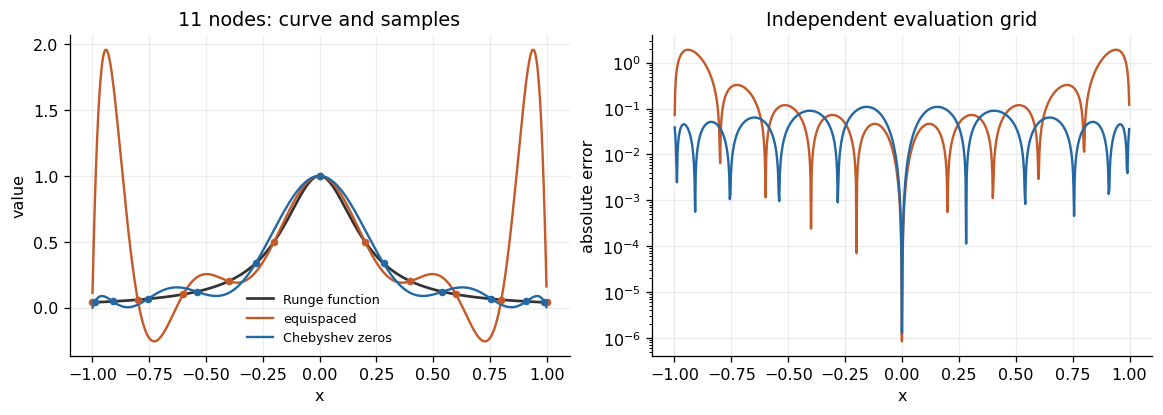

In [6]:
grid = -1 + 2 * (np.arange(801) + 0.371) / 801
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(grid, runge(grid), color="0.2", linewidth=1.7, label="Runge function")
for family, color in (("equispaced", "#c45a29"), ("Chebyshev zeros", "#2468a3")):
    nodes = runge_nodes(11, family)
    assert np.min(abs(grid[:, None] - nodes)) > 1e-12
    estimate, _ = runge_reference(nodes, grid)
    axes[0].plot(grid, estimate, color=color, label=family)
    axes[0].scatter(nodes, runge(nodes), color=color, s=14, zorder=3)
    axes[1].semilogy(grid, np.maximum(abs(estimate - runge(grid)), 1e-16),
                     color=color, label=family)
axes[0].set(xlabel="x", ylabel="value", title="11 nodes: curve and samples")
axes[1].set(xlabel="x", ylabel="absolute error", title="Independent evaluation grid")
axes[0].legend(frameon=False, fontsize=8)
plt.show()

## 2.2 最小二乘与切比雪夫逼近

对满列秩矩阵 $A=U\Sigma V^\mathsf{T}$，用 $c=V\Sigma^{-1}U^\mathsf{T}y$ 独立投影，用奇异值比计算 $\kappa_2(A)$。用 $T_k(z)=\cos(k\arccos z)$ 生成另一种基。比较同一数据上拟合空间、训练误差和区间网格误差。A1 的训练量是二范数，A2 报最大绝对残差，两项保留各自口径。

A2 的评价网格没有参与拟合，正文已披露其中 8 点与训练点重合。这里用有理数集合确认重合点，再从评价集合剔除，检验过拟合结论对网格选择是否敏感。

In [7]:
def design_matrix(points, degree, family, domain):
    points = np.asarray(points)
    powers = np.arange(degree + 1)
    if family == "power":
        return points[:, None] ** powers
    left, right = domain
    mapped = 2 * (points - left) / (right - left) - 1
    return np.cos(np.arccos(mapped)[:, None] * powers)


def svd_fit(matrix, observations):
    left, values, right_t = np.linalg.svd(matrix, full_matrices=False)
    rank_tol = np.finfo(float).eps * max(matrix.shape) * values[0]
    if values.size < matrix.shape[1] or values[-1] <= rank_tol:
        raise ValueError("Rank-deficient design")
    return right_t.T @ ((left.T @ observations) / values), values[0] / values[-1]


def ls_measure(x, y, grid, degree, family, domain):
    matrix = design_matrix(x, degree, family, domain)
    coefficients, condition = svd_fit(matrix, y)
    train = matrix @ coefficients - y
    predictions = design_matrix(grid, degree, family, domain) @ coefficients
    error = np.max(abs(predictions - np.exp(grid)))
    return condition, train, error, predictions


x = np.array([-1.0, 0.0, 1.0])
matrix = design_matrix(x, 1, "power", (-1, 1))
coefficients, _ = svd_fit(matrix, 2 + 3 * x)
np.testing.assert_allclose(coefficients, [2.0, 3.0], atol=1e-12, rtol=0)
rank_deficient = design_matrix([0.0, 0.0, 1.0], 2, "power", (-1, 1))
try:
    svd_fit(rank_deficient, np.ones(3))
except ValueError as error:
    print("Boundary test:", error)
else:
    raise AssertionError("Repeated training points should make this design rank-deficient")

x_a1 = np.linspace(-1, 1, 41)
y_a1 = np.exp(x_a1) + np.random.default_rng(2026).normal(0, 0.015, 41)
grid_a1 = -1 + 2 * (np.arange(2001) + 0.371) / 2001
predictions_a1 = []
print("A1, degree 12: condition, training L2 residual, grid max error")
for row in evidence["a1"]["least_squares"]["rows"]:
    cond, train, error, prediction = ls_measure(
        x_a1, y_a1, grid_a1, 12, row["basis"], (-1, 1),
    )
    actual = [row["condition_2"], row["residual_2"], row["grid_max_error"]]
    expected = [cond, np.linalg.norm(train), error]
    np.testing.assert_allclose(actual, expected, atol=1e-10, rtol=1e-8)
    predictions_a1.append(prediction)
    print(f"{row['basis']:>9} {cond:13.6g} {expected[1]:13.6g} {error:13.6g}")
basis_difference = np.max(abs(predictions_a1[0] - predictions_a1[1]))
assert basis_difference < 1e-10
print(f"Prediction difference between bases: {basis_difference:.3g}")
for row in evidence["a1"]["least_squares"]["degree_comparison"]:
    _, train, error, _ = ls_measure(x_a1, y_a1, grid_a1, row["degree"], "chebyshev", (-1, 1))
    np.testing.assert_allclose([np.linalg.norm(train), error],
                               [row["residual_2"], row["grid_max_error"]],
                               atol=1e-10, rtol=1e-8)
    print(f"d={row['degree']:>2}: train L2={np.linalg.norm(train):.6g}, grid max={error:.6g}")

Boundary test: Rank-deficient design
A1, degree 12: condition, training L2 residual, grid max error
    power       16674.7     0.0693263     0.0189213
chebyshev       2.45887     0.0693263     0.0189213
Prediction difference between bases: 2.2e-14
d= 3: train L2=0.0777356, grid max=0.0115407
d=12: train L2=0.0693263, grid max=0.0189213
d=30: train L2=0.0453763, grid max=28.2171


In [8]:
x_a2 = np.linspace(0, 1, 15)
y_a2 = np.exp(x_a2) + np.random.default_rng(2026).normal(0, 0.03, 15)
grid_a2 = np.linspace(0, 1, 400)
train_set = {Fraction(i, 14) for i in range(15)}
valid_mask = np.array([Fraction(j, 399) not in train_set for j in range(400)])
assert valid_mask.sum() == 392

print("A2: degree, monomial condition, Chebyshev condition")
for degree, actual in evidence["a2_first"]["conditioning"].items():
    degree = int(degree)
    results = [ls_measure(x_a2, y_a2, grid_a2, degree, family, (0, 1))
               for family in ("power", "chebyshev")]
    cond_power, cond_cheb = [result[0] for result in results]
    if degree <= 9:
        np.testing.assert_allclose(cond_power, actual[0], atol=1e-10, rtol=1e-8)
    np.testing.assert_allclose(cond_cheb, actual[1], atol=1e-10, rtol=1e-8)
    print(f"{degree:2d}  {cond_power:14.6e} {cond_cheb:14.6e}")
print(f"Training/evaluation overlap: {400 - valid_mask.sum()} of 400 evaluation points")
print("A2: source run and independent Chebyshev-SVD check")
for degree in (3, 6, 9, 12, 14):
    original = evidence["a2_first"]["degree_errors"][str(degree)]
    _, train, max_error, _ = ls_measure(x_a2, y_a2, grid_a2, degree, "chebyshev", (0, 1))
    _, _, disjoint_error, _ = ls_measure(
        x_a2, y_a2, grid_a2[valid_mask], degree, "chebyshev", (0, 1),
    )
    if degree <= 9:
        np.testing.assert_allclose(
            [np.max(abs(train)), max_error],
            [original["train_max_residual"], original["test_max_error"]],
            atol=1e-10, rtol=1e-8,
        )
    print(f"d={degree:2d}: A residual={original['train_max_residual']:.6e}, "
          f"A grid={original['test_max_error']:.6e}, B full grid={max_error:.6e}, "
          f"B disjoint={disjoint_error:.6e}")
    if degree == 14:
        assert np.max(abs(train)) < 1e-12 and disjoint_error > 0.5
print(f"Normal equation measured condition at d=9: "
      f"{evidence['a2_first']['normal_equation']['condition']:.6e}")

A2: degree, monomial condition, Chebyshev condition
 3    1.054687e+02   1.820984e+00
 6    1.819328e+04   1.845047e+00
 9    4.628255e+06   2.987622e+00
12    2.412656e+09   1.651080e+01
Training/evaluation overlap: 8 of 400 evaluation points
A2: source run and independent Chebyshev-SVD check
d= 3: A residual=5.168196e-02, A grid=2.044732e-02, B full grid=2.044732e-02, B disjoint=2.009118e-02
d= 6: A residual=5.202705e-02, A grid=2.530163e-02, B full grid=2.530163e-02, B disjoint=2.530163e-02
d= 9: A residual=3.418950e-02, A grid=3.150494e-02, B full grid=3.150494e-02, B disjoint=3.150494e-02
d=12: A residual=5.638855e-03, A grid=1.764085e-01, B full grid=1.764085e-01, B disjoint=1.764085e-01
d=14: A residual=1.655799e-07, A grid=9.688469e-01, B full grid=9.688469e-01, B disjoint=9.688469e-01
Normal equation measured condition at d=9: 2.141852e+13


## 2.3 数值积分、差分与自动微分

复合梯形对 $x^2$ 的单段误差 $T-I=h^3/6$，$N$ 个等宽区间合计 $(b-a)^3/(6N^2)$。$[0,1]$ 真积分为 $1/3$，固定 $N$ 放大区间十倍时误差倍数为 $10^3$。二次插值节点取 $u,u+h,u+2h$ 时，积分权重为 $(h/3)(1,4,1)$。

对中心差分，Taylor 展开给出 $D_hF-F'=(h^2/6)F'''+O(h^4)$。用解析导数对照 A1 的 Dual、Graph、Jet2 与 A2 的 PyTorch AD。单独检查短步长的舍入误差，并复算正文及题解的具体数字。

In [9]:
def trapezoid(function, left, right, panels):
    width = (right - left) / panels
    interior = fsum(function(left + k * width) for k in range(1, panels))
    return width * (0.5 * (function(left) + function(right)) + interior)


truth = Fraction(1, 3)
a1_quad = {row["N"]: row["T_N"] for row in evidence["a1"]["differentiation"]["trapezoid"]}
a2_quad = {row["n"]: row["T_n"] for row in evidence["a2_last"]["quadrature"]}
print(f"{'N':>4}  {'closed form':>16}  {'A1':>16}  {'A2':>16}  {'E_N':>12}")
for panels in (4, 8, 16, 32, 64, 128):
    closed = float(truth + Fraction(1, 6 * panels**2))
    a1_value = a1_quad.get(panels, float("nan"))
    a2_value = a2_quad[panels]
    a1_text = f"{a1_value:.12f}" if panels in a1_quad else "—"
    print(f"{panels:4d}  {closed:16.12f}  {a1_text:>16}  {a2_value:16.12f}  "
          f"{float(Fraction(1, 6 * panels**2)):12.5e}")
    np.testing.assert_allclose(trapezoid(lambda x: x*x, 0, 1, panels), closed, atol=1e-14, rtol=0)
    if panels in a1_quad:
        np.testing.assert_allclose(a1_value, closed, atol=1e-14, rtol=0)
    np.testing.assert_allclose(a2_value, closed, atol=1e-14, rtol=0)

np.testing.assert_allclose(trapezoid(lambda x: 2*x + 1, 0, 1, 1), 2.0, atol=1e-14, rtol=0)
small = trapezoid(lambda x: x*x, 0, 1, 8) - 1/3
large = trapezoid(lambda x: x*x, 0, 10, 8) - 1000/3
print(f"x^2, N=8, interval lengths 1 and 10: errors {small:.12g}, {large:.12g}")
print(f"Interval scale error ratio: {large/small:.9g}")
assert abs(large / small - 1000) < 1e-8
print(f"Panel integral of (x-u)(x-v), width 1/4: {float(-Fraction(1, 4)**3/6):.12g}")

half_width = 0.5
simpson_sum = 0**2 + 4 * half_width**2 + 1**2
text_value = half_width * simpson_sum / 6
correct_value = half_width * simpson_sum / 3
print(f"Simpson on x^2, [0,1]: printed half-width formula={text_value:.12g}, "
      f"correct={correct_value:.12g}")
assert abs(correct_value - 1/3) <= 1e-14 and abs(text_value - 1/3) > 0.1

errors_sqrt = [abs(trapezoid(sqrt, 0, 1, n) - 2/3) for n in (32, 64, 128, 256, 512)]
orders_sqrt = [log2(a / b) for a, b in zip(errors_sqrt, errors_sqrt[1:])]
print("sqrt(x) observed orders:", [round(order, 6) for order in orders_sqrt])
print("A2 exp(x) observed orders:", [round(order, 6) for order in evidence["a2_last"]["exp_orders"]])

   N       closed form                A1                A2           E_N
   4    0.343750000000    0.343750000000    0.343750000000   1.04167e-02
   8    0.335937500000    0.335937500000    0.335937500000   2.60417e-03
  16    0.333984375000    0.333984375000    0.333984375000   6.51042e-04
  32    0.333496093750    0.333496093750    0.333496093750   1.62760e-04
  64    0.333374023438    0.333374023438    0.333374023438   4.06901e-05
 128    0.333343505859                 —    0.333343505859   1.01725e-05
x^2, N=8, interval lengths 1 and 10: errors 0.00260416666667, 2.60416666667
Interval scale error ratio: 1000
Panel integral of (x-u)(x-v), width 1/4: -0.00260416666667
Simpson on x^2, [0,1]: printed half-width formula=0.166666666667, correct=0.333333333333
sqrt(x) observed orders: [1.484562, 1.489182, 1.492399, 1.494649]
A2 exp(x) observed orders: [1.998874, 1.999718, 1.99993, 1.999982, 1.999996]


F(0.7)=2.484378595642, F'=3.249018709524647, F''=2.855991683875250
D_0.1=3.241716680946303, D_0.1 - F'=-7.302028578344e-03
A1 table 3.2563, difference from independent reference 0.014583319
Taylor sign: F'''/6=-0.726771020; (D_0.002 - F')/h^2=-0.726772390
A1 Dual / Graph / Jet2 agree with reference. A2 AD grid max error=4.441e-16
Float64 ulp at x=0.7: 1.1102e-16. Does x+1e-16 equal x? False


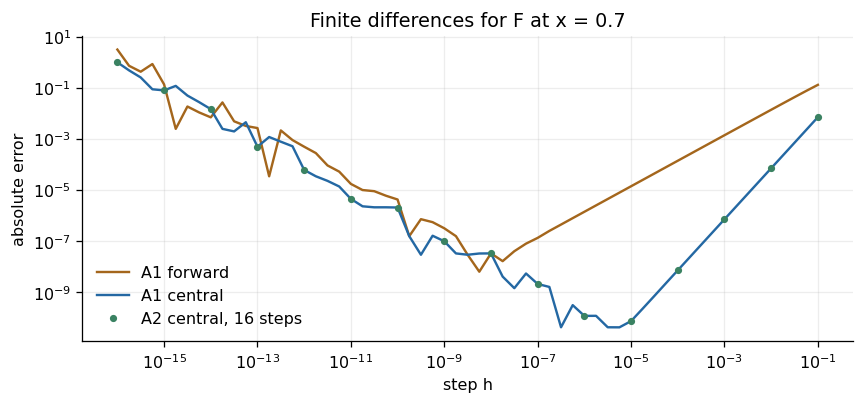

In [10]:
def f(x):
    return sin(x*x) + exp(x)


def central(function, x, step):
    return (function(x + step) - function(x - step)) / (2 * step)


x0 = 0.7
exact_d1 = 2*x0*cos(x0*x0) + exp(x0)
exact_d2 = 2*cos(x0*x0) - 4*x0*x0*sin(x0*x0) + exp(x0)
exact_d3 = exp(x0) - 12*x0*sin(x0*x0) - 8*x0**3*cos(x0*x0)
at_point_one = central(f, x0, 0.1)
print(f"F(0.7)={f(x0):.12f}, F'={exact_d1:.15f}, F''={exact_d2:.15f}")
print(f"D_0.1={at_point_one:.15f}, D_0.1 - F'={at_point_one-exact_d1:+.12e}")
print(f"A1 table 3.2563, difference from independent reference {3.2563-at_point_one:.8g}")
print(f"Taylor sign: F'''/6={exact_d3/6:+.9f}; "
      f"(D_0.002 - F')/h^2={(central(f, x0, 0.002)-exact_d1)/0.002**2:+.9f}")
assert abs(3.2563 - at_point_one) > 5e-5
assert abs((central(f, x0, 0.002) - exact_d1)/0.002**2 - exact_d3/6) < 5e-6
a1_diff = evidence["a1"]["differentiation"]
a2_diff = evidence["a2_last"]["differentiation"]
np.testing.assert_allclose(
    [a1_diff["dual_d1"], a1_diff["reverse_d1"], a1_diff["jet_d2"], a2_diff["ad"]],
    [exact_d1, exact_d1, exact_d2, exact_d1], atol=1e-12, rtol=0,
)
np.testing.assert_allclose(a2_diff["central_difference"][0]["central_difference"],
                           at_point_one, atol=1e-12, rtol=0)
print(f"A1 Dual / Graph / Jet2 agree with reference. A2 AD grid max error={a2_diff['grid_ad_error']:.3e}")
print(f"Float64 ulp at x=0.7: {ulp(x0):.4e}. Does x+1e-16 equal x? {x0 + 1e-16 == x0}")

a1_scan = a1_diff["difference"]
a2_scan = a2_diff["central_difference"]
figure, axis = plt.subplots(figsize=(7.4, 3.4), layout="constrained")
axis.loglog(a1_scan["h"], a1_scan["forward_error"], color="#a4661c", label="A1 forward")
axis.loglog(a1_scan["h"], a1_scan["central_error"], color="#2468a3", label="A1 central")
axis.loglog([row["h"] for row in a2_scan], [row["abs_error"] for row in a2_scan],
            "o", markersize=3.5, color="#3a8262", label="A2 central, 16 steps")
axis.set(xlabel="step h", ylabel="absolute error", title="Finite differences for F at x = 0.7")
axis.legend(frameon=False)
plt.show()

## 2.4 网络逼近、输入导数与 PINN 残差

测试目标为 $g=\sin(\pi x)$，解析参考为 $g'=\pi\cos(\pi x)$、$g''=-\pi^2\sin(\pi x)$。独立传播每层的值、一阶导和二阶导，复算两稿各自网格上的误差。对 $\tanh(a)$ 记 $t=\tanh(a)$，则 $t'=(1-t^2)a'$，$t''=(1-t^2)[a''-2t(a')^2]$。

训练目标是函数值误差。A2 在训练结束后计算 Poisson 残差 $-u_{xx}-\pi^2\sin(\pi x)$，并单独给边界值。两个训练预算与测试网格各异，比较结果只说明各自实验中的误差层次。

In [11]:
def differentiate_network(points, layers):
    value = np.asarray(points).reshape(1, -1)
    first = np.ones_like(value)
    second = np.zeros_like(value)
    for index, (weight, bias) in enumerate(layers):
        weight = np.asarray(weight)
        bias = np.asarray(bias).reshape(-1, 1)
        affine = weight @ value + bias
        affine_first = weight @ first
        affine_second = weight @ second
        if index == len(layers) - 1:
            value, first, second = affine, affine_first, affine_second
        else:
            value = np.tanh(affine)
            local = 1 - value**2
            first = local * affine_first
            second = local * (affine_second - 2 * value * affine_first**2)
    return np.vstack([value.ravel(), first.ravel(), second.ravel()])


def target_derivatives(grid):
    phase = np.pi * grid
    return np.vstack([np.sin(phase), np.pi*np.cos(phase), -np.pi**2*np.sin(phase)])


def maximum_errors(grid, predictions):
    return np.max(abs(predictions - target_derivatives(grid)), axis=1)


a1_network = evidence["a1"]["network"]
p = a1_network["params"]
layers_a1 = [(np.array(p["w"])[:, None], p["b"]), (np.array(p["a"])[None, :], p["c"])]
weights = evidence["a2_weights"]
layers_a2 = [(weights[f"{index}.weight"], weights[f"{index}.bias"]) for index in (0, 2, 4)]
grid_a1 = -1 + 2 * (np.arange(2001) + 0.371) / 2001
grid_a2 = -1 + 2 * (np.arange(400) + 0.5) / 400
pred_a1 = differentiate_network(grid_a1, layers_a1)
pred_a2 = differentiate_network(grid_a2, layers_a2)

for grid, train_count in [(grid_a1, 81), (grid_a2, 41)]:
    assert np.min(abs(grid[:, None] - np.linspace(-1, 1, train_count))) > 1e-12

errors_a1 = maximum_errors(grid_a1, pred_a1)
errors_a2 = maximum_errors(grid_a2, pred_a2)
published_a1 = [a1_network["independent_grid_max_errors"][key]
                for key in ("value", "first_derivative", "second_derivative")]
np.testing.assert_allclose(errors_a1, published_a1, atol=1e-10, rtol=0)
a2_network = evidence["a2_last"]["network"]
np.testing.assert_allclose(errors_a2, [row["max_abs_error"] for row in a2_network["errors"]],
                           atol=1e-10, rtol=0)

sample = np.asarray(evidence["a2_ad_samples"])
sample_output = differentiate_network(sample[:, 0], layers_a2)
ad_difference = np.max(abs(sample_output - sample[:, 1:].T), axis=1)
np.testing.assert_allclose(sample_output, sample[:, 1:].T, atol=1e-10, rtol=0)
residual = -pred_a2[2] - np.pi**2 * np.sin(np.pi*grid_a2)
residual_rmse = np.sqrt(np.mean(residual**2))
boundary = differentiate_network([-1, 1], layers_a2)[0]
np.testing.assert_allclose(residual_rmse, a2_network["poisson_residual_rmse"], atol=1e-10, rtol=0)
np.testing.assert_allclose(boundary, a2_network["boundary_values"], atol=1e-10, rtol=0)

print("Maximum grid errors (value, first derivative, second derivative)")
print("A1:", np.array2string(errors_a1, precision=9))
print("A2:", np.array2string(errors_a2, precision=9))
print("A2 independent chain versus AD at five test points:", ad_difference)
print(f"A2 Poisson residual RMSE={residual_rmse:.9g}, u(-1), u(1)={boundary}")

Maximum grid errors (value, first derivative, second derivative)
A1: [0.002864758 0.117168496 1.646941912]
A2: [0.000413467 0.015226983 0.356181074]
A2 independent chain versus AD at five test points: [2.22044605e-16 8.88178420e-16 1.94289029e-15]
A2 Poisson residual RMSE=0.0923873139, u(-1), u(1)=[-1.48523874e-04  4.51119556e-05]


sin(10x)/10: witness errors [0.1, 1.0, 10.0]
sin(100x)/100: witness errors [0.01, 1.0, 100.0]
sin(1000x)/1000: witness errors [0.001, 1.0, 1000.0]
ReLU at x=0, h=0.1: second difference 10
ReLU at x=0, h=0.01: second difference 100
ReLU at x=0, h=0.001: second difference 1000


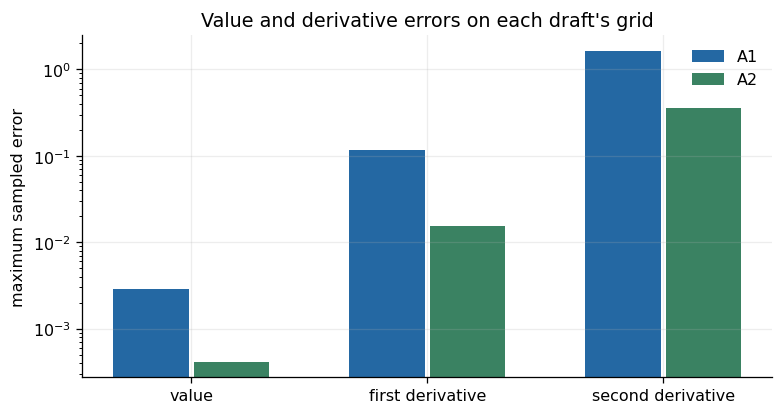

In [12]:
for frequency in (10, 100, 1000):
    witness = pi / (2*frequency)
    values = [sin(frequency*witness)/frequency, cos(frequency*0), frequency*sin(frequency*witness)]
    np.testing.assert_allclose(values, [1/frequency, 1.0, frequency], atol=1e-12, rtol=0)
    print(f"sin({frequency}x)/{frequency}: witness errors {values}")
for step in (0.1, 0.01, 0.001):
    kink_difference = (max(step, 0) - 2*max(0, 0) + max(-step, 0)) / step**2
    print(f"ReLU at x=0, h={step:g}: second difference {kink_difference:.9g}")
    np.testing.assert_allclose(kink_difference, 1/step, atol=1e-12, rtol=0)

figure, axis = plt.subplots(figsize=(6.7, 3.5), layout="constrained")
orders = np.arange(3)
axis.bar(orders - 0.17, errors_a1, width=0.32, color="#2468a3", label="A1")
axis.bar(orders + 0.17, errors_a2, width=0.32, color="#3a8262", label="A2")
axis.set(yscale="log", ylabel="maximum sampled error",
         title="Value and derivative errors on each draft's grid")
axis.set_xticks(orders, ["value", "first derivative", "second derivative"])
axis.legend(frameon=False)
plt.show()

## 首轮结论与交接

三份 A 稿 Notebook 都从新内核完成了原有代码单元。A1 的主实验数值与独立对照吻合，正文和题解仍有已定位的积分与差分问题。A2 的四个主题均有实测证据，2.2 的残差显示和评价点口径见修正清单。组员签认、A 的修复提交、第二轮复测及版本选用结论在收到新材料后更新。